# UAE E-Commerce Fraud Detection, Revenue Analytics & 4-Month Sales Forecast
## Enhanced senior-level project notebook

**Purpose:** strengthen the fraud proof-of-concept, investigate leakage and invalid account ages, document data provenance, quantify fraud-control scenarios, analyze current sales/GTV and forecast the next four months, and provide a responsible path toward deep learning and cloud deployment.

### Important evidence boundaries
- The supplied dataset is **synthetic** (`synthetic:ecom-fraud-uae-v1`), not verified production data.
- A synthetic dataset cannot establish production provenance. This notebook creates a provenance evidence checklist and hash manifest; a real source owner must supply signed extraction/source evidence.
- `amount_aed` is treated as **gross transaction value (GTV)**. It is not automatically accounting revenue. Revenue is only estimated below using an explicitly configurable take-rate assumption. Replace that assumption with Finance-approved recognized-revenue data.
- Forecasts are based on the historical period in the dataset. They are scenario estimates, not verified future sales.
- The notebook never invents customer review text. NLP runs only if a genuine text field is present and approved for use.
- Deep learning is optional and CPU-friendly. Classical forecasting remains the baseline.

## 0. Environment and reproducibility

In [1]:
import os, sys, json, hashlib, warnings, platform
from pathlib import Path
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)

print("Python:", sys.version)
print("Platform:", platform.platform())
print("Run UTC:", datetime.now(timezone.utc).isoformat())

Python: 3.13.14 (tags/v3.13.14:fd17997, Jun 10 2026, 13:03:48) [MSC v.1944 64 bit (AMD64)]
Platform: Windows-10-10.0.19045-SP0
Run UTC: 2026-11-06T07:57:31.616018+00:00


## 1. Load data and validate schema

In [2]:
# Update this path if your CSV is stored elsewhere.
DATA_PATH = Path("uae_ecom_fraud_100k.csv")
if not DATA_PATH.exists():
    # Search the notebook's working directory for a likely matching CSV.
    candidates = list(Path.cwd().glob("*fraud*.csv"))
    if candidates:
        DATA_PATH = candidates[0]
    else:
        raise FileNotFoundError(
            f"Dataset not found at {DATA_PATH.resolve()}. "
            "Place uae_ecom_fraud_100k.csv beside this notebook or update DATA_PATH."
        )

df_raw = pd.read_csv(DATA_PATH)
print("Shape:", df_raw.shape)
display(df_raw.head())
print("Columns:", df_raw.columns.tolist())

Shape: (100000, 36)


,transaction_id,user_id,timestamp_utc,amount_aed,currency,payment_method,device_type,browser,merchant_category,items_count,avg_item_price,shipping_city,billing_city,shipping_billing_match,ip_address,ip_risk_score,card_present,bin_country,card_age_days,card_country_match,email_domain,user_prev_chargebacks,user_is_high_risk,user_account_age_days,transactions_last_24h,transactions_last_1h,local_hour,odd_hour,is_fraud,fraud_flag_ip,fraud_flag_mismatch,fraud_flag_velocity,fraud_flag_new_account,fraud_flag_prev_cb,fraud_flag_odd_hour,data_source
0,500086758,1000466,2024-01-01T00:02:03Z,71.47,AED,card,desktop,Chrome,Pharmacy,3,23.82,Dubai,Dubai,1,144.108.182.242,35.3,0,AE,85,1,gmail.com,0,0,365,0,0,4,1,0,0,0,0,0,0,1,synthetic:ecom-fraud-uae-v1
1,500060464,1002828,2024-01-01T00:03:11Z,70.25,AED,card,mobile,Chrome,Groceries,1,70.25,Abu Dhabi,Abu Dhabi,1,104.37.234.72,30.2,0,SA,123,0,outlook.com,0,0,-192,0,0,4,1,0,0,0,0,1,0,1,synthetic:ecom-fraud-uae-v1
2,500039909,1010349,2024-01-01T00:04:10Z,116.25,AED,bank_transfer,desktop,Chrome,Beauty,2,58.12,Cairo,Cairo,1,89.169.143.66,32.7,0,PK,542,0,gmail.com,0,0,1744,0,0,4,1,0,0,0,0,0,0,1,synthetic:ecom-fraud-uae-v1
3,500074412,1015360,2024-01-01T00:05:14Z,99.41,AED,apple_pay,mobile,Safari,Toys,2,49.70,Mumbai,Mumbai,1,37.54.200.109,30.3,0,EG,981,0,outlook.com,0,0,102,0,0,4,1,0,0,0,0,0,0,1,synthetic:ecom-fraud-uae-v1
4,500038110,1022253,2024-01-01T00:11:03Z,529.40,AED,card,desktop,Safari,Travel,2,264.70,Dubai,Dubai,1,18.172.52.222,18.5,0,AE,515,1,gmail.com,1,1,-59,0,0,4,1,0,0,0,0,1,1,1,synthetic:ecom-fraud-uae-v1


Columns: ['transaction_id', 'user_id', 'timestamp_utc', 'amount_aed', 'currency', 'payment_method', 'device_type', 'browser', 'merchant_category', 'items_count', 'avg_item_price', 'shipping_city', 'billing_city', 'shipping_billing_match', 'ip_address', 'ip_risk_score', 'card_present', 'bin_country', 'card_age_days', 'card_country_match', 'email_domain', 'user_prev_chargebacks', 'user_is_high_risk', 'user_account_age_days', 'transactions_last_24h', 'transactions_last_1h', 'local_hour', 'odd_hour', 'is_fraud', 'fraud_flag_ip', 'fraud_flag_mismatch', 'fraud_flag_velocity', 'fraud_flag_new_account', 'fraud_flag_prev_cb', 'fraud_flag_odd_hour', 'data_source']


In [3]:
# Normalize known date/label fields without silently renaming source columns.
DATE_CANDIDATES = ["timestamp_utc", "timestamp", "transaction_timestamp", "created_at"]
DATE_COL = next((c for c in DATE_CANDIDATES if c in df_raw.columns), None)
if DATE_COL is None:
    raise KeyError(f"No transaction timestamp found. Expected one of {DATE_CANDIDATES}")

LABEL_COL = "is_fraud" if "is_fraud" in df_raw.columns else (
    "fraud" if "fraud" in df_raw.columns else None
)
if LABEL_COL is None:
    raise KeyError("Fraud label column is missing; expected is_fraud or fraud.")

AMOUNT_COL = "amount_aed" if "amount_aed" in df_raw.columns else None
if AMOUNT_COL is None:
    raise KeyError("amount_aed is required for GTV and sales analysis.")

df = df_raw.copy()
df[DATE_COL] = pd.to_datetime(df[DATE_COL], errors="coerce", utc=True)
df[LABEL_COL] = pd.to_numeric(df[LABEL_COL], errors="coerce")
df[AMOUNT_COL] = pd.to_numeric(df[AMOUNT_COL], errors="coerce")
df = df.dropna(subset=[DATE_COL, LABEL_COL, AMOUNT_COL]).copy()
df[LABEL_COL] = df[LABEL_COL].astype(int)
df = df[df[LABEL_COL].isin([0, 1])].copy()
df = df.sort_values(DATE_COL).reset_index(drop=True)

print("Rows after basic required-field validation:", len(df))
print("Date range:", df[DATE_COL].min(), "to", df[DATE_COL].max())
print("Fraud rate:", round(df[LABEL_COL].mean()*100, 3), "%")
print("Negative amounts:", int((df[AMOUNT_COL] < 0).sum()))
display(df[[DATE_COL, AMOUNT_COL, LABEL_COL]].describe(include="all"))

Rows after basic required-field validation: 100000
Date range: 2024-01-01 00:02:03+00:00 to 2024-12-31 23:54:53+00:00
Fraud rate: 8.211 %
Negative amounts: 0


,timestamp_utc,amount_aed,is_fraud
count,100000,100000.000000,100000.000000
mean,2024-07-02 09:13:32.290369+00:00,162.863922,0.082110
min,2024-01-01 00:02:03+00:00,1.260000,0.000000
25%,2024-04-01 14:22:05.500000+00:00,41.370000,0.000000
50%,2024-07-02 16:28:53+00:00,82.100000,0.000000
75%,2024-10-02 04:24:29+00:00,164.885000,0.000000
max,2024-12-31 23:54:53+00:00,28785.920000,1.000000
std,NaN,401.181135,0.274534


## 2. Data provenance: distinguish synthetic origin from verified production provenance

In [4]:
def sha256_file(path, chunk_size=1024*1024):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(chunk_size), b""):
            h.update(chunk)
    return h.hexdigest()

provenance = {
    "dataset_file": str(DATA_PATH.resolve()),
    "sha256": sha256_file(DATA_PATH),
    "file_size_bytes": DATA_PATH.stat().st_size,
    "row_count_loaded": int(len(df_raw)),
    "columns": df_raw.columns.tolist(),
    "timestamp_column": DATE_COL,
    "fraud_label_column": LABEL_COL,
    "amount_column": AMOUNT_COL,
    "observed_date_min_utc": str(df[DATE_COL].min()),
    "observed_date_max_utc": str(df[DATE_COL].max()),
    "declared_data_source_values": (
        sorted(df_raw["data_source"].dropna().astype(str).unique().tolist())
        if "data_source" in df_raw.columns else ["NOT PROVIDED"]
    ),
    "classification": "SYNTHETIC / PROOF OF CONCEPT unless independently verified",
    "source_system_owner": "NOT PROVIDED",
    "extraction_job_id": "NOT PROVIDED",
    "extraction_timestamp_utc": datetime.now(timezone.utc).isoformat(),
    "source_query_or_api_version": "NOT PROVIDED",
    "consent_and_legal_basis": "REQUIRES REVIEW",
    "production_provenance_verified": False
}
display(pd.Series(provenance, name="Value").to_frame())
with open("data_provenance_manifest.json", "w", encoding="utf-8") as f:
    json.dump(provenance, f, indent=2, default=str)
print("Saved data_provenance_manifest.json")

,Value
dataset_file,C:\Users\IQRA TRADERS\Desktop\desktop\5 projec...
sha256,a4dd97494273ef6aeed193737b2597bdf86d2ca3fe559b...
file_size_bytes,20610879
row_count_loaded,100000
columns,"[transaction_id, user_id, timestamp_utc, amoun..."
timestamp_column,timestamp_utc
fraud_label_column,is_fraud
amount_column,amount_aed
observed_date_min_utc,2024-01-01 00:02:03+00:00
observed_date_max_utc,2024-12-31 23:54:53+00:00


Saved data_provenance_manifest.json


### Production provenance evidence required
A production-data owner must complete and approve: originating system/table, data owner, extraction query/API version, extraction time, source timezone, event-time semantics, schema version, transformation code commit, row-count reconciliation, access authorization, privacy/legal basis, retention policy, and an immutable source checksum. A checksum proves file integrity after hashing; it does **not** prove the data came from the claimed production system.

## 3. Data quality profile and negative account-age investigation

In [6]:
missing = df.isna().sum().sort_values(ascending=False)
quality = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing_count": df.isna().sum(),
    "missing_pct": (df.isna().mean()*100).round(2),
    "n_unique": df.nunique(dropna=True)
}).sort_values(["missing_pct", "n_unique"], ascending=[False, True])
display(quality)

AGE_COL = "user_account_age_days"
if AGE_COL in df.columns:
    age = pd.to_numeric(df[AGE_COL], errors="coerce")
    negative_age = df.loc[age < 0].copy()
    print("Negative account ages:", len(negative_age))
    print("Negative age %:", round((age < 0).mean()*100, 3))
    display(negative_age[[c for c in [AGE_COL, DATE_COL, "user_id", "is_fraud"] if c in df.columns]].head(20))
    print("Negative age distribution:")
    display(age[age < 0].describe())
else:
    negative_age = pd.DataFrame()
    print("Account-age field not found.")

,dtype,missing_count,missing_pct,n_unique
currency,str,0,0.0,1
fraud_flag_velocity,int64,0,0.0,1
data_source,str,0,0.0,1
shipping_billing_match,int64,0,0.0,2
card_present,int64,0,0.0,2
card_country_match,int64,0,0.0,2
user_is_high_risk,int64,0,0.0,2
transactions_last_1h,int64,0,0.0,2
odd_hour,int64,0,0.0,2
is_fraud,int64,0,0.0,2


Negative account ages: 16606
Negative age %: 16.606


,user_account_age_days,timestamp_utc,user_id,is_fraud
1,-192,2024-01-01 00:03:11+00:00,1002828,0
4,-59,2024-01-01 00:11:03+00:00,1022253,0
6,-246,2024-01-01 00:15:14+00:00,1004416,0
8,-335,2024-01-01 00:32:42+00:00,1001159,0
9,-244,2024-01-01 00:34:20+00:00,1011250,0
11,-266,2024-01-01 00:38:04+00:00,1008580,0
12,-249,2024-01-01 00:43:54+00:00,1027989,0
20,-121,2024-01-01 01:37:28+00:00,1024603,0
22,-209,2024-01-01 01:46:57+00:00,1021541,1
23,-92,2024-01-01 01:47:28+00:00,1003372,0


Negative age distribution:


count    16606.000000
mean      -185.831386
std        106.796342
min       -365.000000
25%       -280.000000
50%       -187.000000
75%        -93.000000
max         -1.000000
Name: user_account_age_days, dtype: float64

### Negative account-age root-cause workflow
Do not silently convert negative ages to zero or drop them. Reconcile:
1. Is account creation time later than transaction time due to timezone conversion?
2. Are account IDs joined to the wrong customer or reused?
3. Is the field a signed offset or corrupted duration?
4. Are synthetic generation rules creating impossible dates?
5. Does the source use event time, ingestion time, or a delayed backfill?

Required evidence: raw `account_created_at`, transaction event timestamp, user key, timezone, source record ID, and generation/transformation code. Until resolved, create an explicit invalid-age indicator and exclude the raw negative value from model features or treat it as missing under a documented policy.

In [7]:
if AGE_COL in df.columns:
    df["account_age_negative_flag"] = (pd.to_numeric(df[AGE_COL], errors="coerce") < 0).astype("int8")
    df["account_age_days_validated"] = pd.to_numeric(df[AGE_COL], errors="coerce").where(
        pd.to_numeric(df[AGE_COL], errors="coerce") >= 0, np.nan
    )
    print(df["account_age_negative_flag"].value_counts(dropna=False))

account_age_negative_flag
0    83394
1    16606
Name: count, dtype: int64


## 4. Point-in-time leakage audit: velocity, IP risk, high-risk status and chargebacks

In [8]:
# A feature is safe only if its value was available at or before the transaction decision time.
# This dataset may contain snapshots without timestamps. Mark those as UNVERIFIED, not PASS.
feature_timestamp_map = {
    "transactions_last_1h": "transactions_last_1h_asof_utc",
    "transactions_last_24h": "transactions_last_24h_asof_utc",
    "ip_risk_score": "ip_risk_score_asof_utc",
    "user_prev_chargebacks": "chargeback_history_asof_utc",
    "user_is_high_risk": "high_risk_status_asof_utc",
}
audit_rows = []
for feature, ts_col in feature_timestamp_map.items():
    if feature not in df.columns:
        status, note = "NOT PRESENT", "Feature absent from dataset."
    elif ts_col not in df.columns:
        status, note = "UNVERIFIED", f"Missing point-in-time timestamp column: {ts_col}"
    else:
        feature_ts = pd.to_datetime(df[ts_col], errors="coerce", utc=True)
        bad = feature_ts.isna() | (feature_ts > df[DATE_COL])
        status = "FAIL" if bad.any() else "PASS"
        note = f"{int(bad.sum())} rows missing or timestamped after transaction."
    audit_rows.append({"feature": feature, "availability_timestamp": ts_col, "audit_status": status, "finding": note})
leakage_audit = pd.DataFrame(audit_rows)
display(leakage_audit)

,feature,availability_timestamp,audit_status,finding
0,transactions_last_1h,transactions_last_1h_asof_utc,UNVERIFIED,Missing point-in-time timestamp column: transa...
1,transactions_last_24h,transactions_last_24h_asof_utc,UNVERIFIED,Missing point-in-time timestamp column: transa...
2,ip_risk_score,ip_risk_score_asof_utc,UNVERIFIED,Missing point-in-time timestamp column: ip_ris...
3,user_prev_chargebacks,chargeback_history_asof_utc,UNVERIFIED,Missing point-in-time timestamp column: charge...
4,user_is_high_risk,high_risk_status_asof_utc,UNVERIFIED,Missing point-in-time timestamp column: high_r...


**Decision rule:** do not use a feature in a production model until its value is reproducibly reconstructed *as of the decision timestamp*. For velocity, recompute from prior events only (`event_time < current_transaction_time`) with a strict lookback window. For chargebacks, use only chargebacks known by decision time; never use eventual outcomes. For IP risk, retain provider score version and lookup timestamp. For high-risk status, retain effective-from/effective-to history. This notebook labels missing timestamp evidence UNVERIFIED.

## 5. Current sales performance: monthly transactions, GTV and revenue proxy

In [9]:
sales = df.copy()
sales["month"] = sales[DATE_COL].dt.tz_convert(None).dt.to_period("M").dt.to_timestamp()
sales["positive_gtv_aed"] = sales[AMOUNT_COL].clip(lower=0)
monthly = sales.groupby("month").agg(
    transactions=(AMOUNT_COL, "size"),
    gtv_aed=("positive_gtv_aed", "sum"),
    average_order_value_aed=("positive_gtv_aed", "mean"),
    fraud_transactions=(LABEL_COL, "sum")
).reset_index()
monthly["fraud_rate_pct"] = monthly["fraud_transactions"] / monthly["transactions"] * 100
monthly["gtv_m_aed"] = monthly["gtv_aed"] / 1_000_000

# IMPORTANT: replace with Finance-approved take rate / recognized revenue logic.
ASSUMED_REVENUE_TAKE_RATE = 0.10  # illustrative 10%; NOT an observed accounting rate
monthly["estimated_revenue_aed"] = monthly["gtv_aed"] * ASSUMED_REVENUE_TAKE_RATE
monthly["revenue_assumption"] = f"GTV x {ASSUMED_REVENUE_TAKE_RATE:.1%} illustrative take rate"
display(monthly)
print("Observed months:", len(monthly))
print("Total observed GTV (AED):", round(monthly["gtv_aed"].sum(), 2))
print("Illustrative revenue proxy (AED):", round(monthly["estimated_revenue_aed"].sum(), 2))

,month,transactions,gtv_aed,average_order_value_aed,fraud_transactions,fraud_rate_pct,gtv_m_aed,estimated_revenue_aed,revenue_assumption
0,2024-01-01,8535,1406303.92,164.769059,707,8.283538,1.406304,140630.392,GTV x 10.0% illustrative take rate
1,2024-02-01,7796,1229427.47,157.699778,641,8.222165,1.229427,122942.747,GTV x 10.0% illustrative take rate
2,2024-03-01,8516,1389463.78,163.159204,698,8.196336,1.389464,138946.378,GTV x 10.0% illustrative take rate
3,2024-04-01,7989,1291270.41,161.631044,607,7.597947,1.291270,129127.041,GTV x 10.0% illustrative take rate
4,2024-05-01,8447,1435846.72,169.983038,724,8.571090,1.435847,143584.672,GTV x 10.0% illustrative take rate
5,2024-06-01,8249,1344279.08,162.962672,706,8.558613,1.344279,134427.908,GTV x 10.0% illustrative take rate
6,2024-07-01,8507,1354819.76,159.259405,680,7.993417,1.354820,135481.976,GTV x 10.0% illustrative take rate
7,2024-08-01,8419,1358516.33,161.363146,677,8.041335,1.358516,135851.633,GTV x 10.0% illustrative take rate
8,2024-09-01,8226,1376191.37,167.297760,696,8.460977,1.376191,137619.137,GTV x 10.0% illustrative take rate
9,2024-10-01,8591,1399635.66,162.918829,700,8.148062,1.399636,139963.566,GTV x 10.0% illustrative take rate


Observed months: 12
Total observed GTV (AED): 16286392.2
Illustrative revenue proxy (AED): 1628639.22


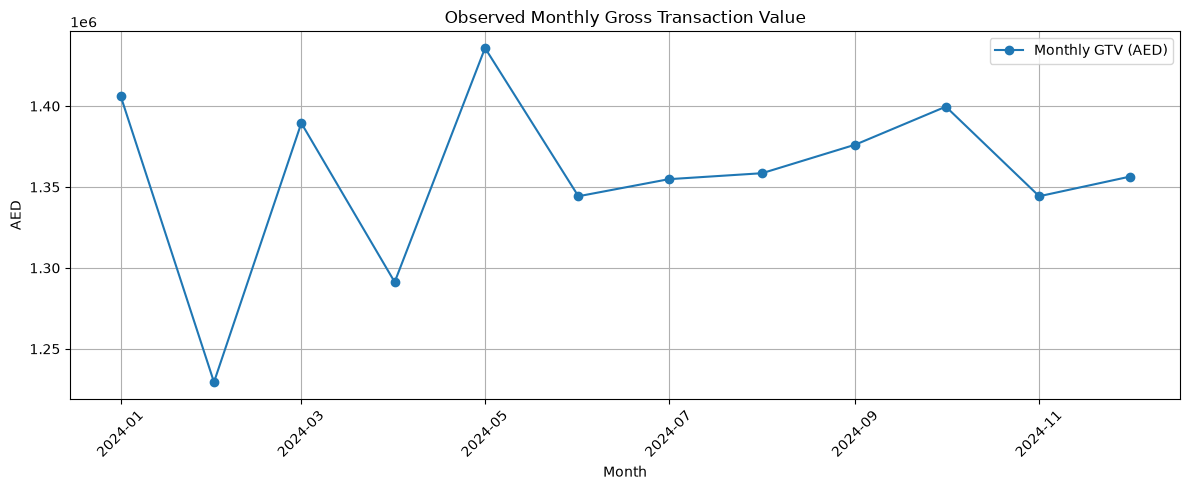

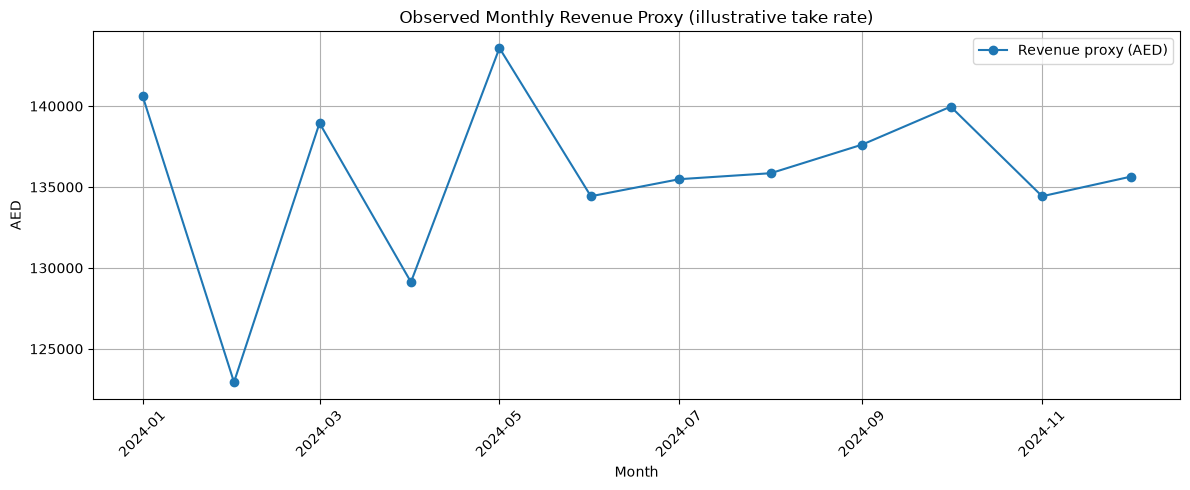

In [10]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(monthly["month"], monthly["gtv_aed"], marker="o", label="Monthly GTV (AED)")
ax.set_title("Observed Monthly Gross Transaction Value")
ax.set_xlabel("Month"); ax.set_ylabel("AED"); ax.grid(True); ax.legend()
plt.xticks(rotation=45); plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(monthly["month"], monthly["estimated_revenue_aed"], marker="o", label="Revenue proxy (AED)")
ax.set_title("Observed Monthly Revenue Proxy (illustrative take rate)")
ax.set_xlabel("Month"); ax.set_ylabel("AED"); ax.grid(True); ax.legend()
plt.xticks(rotation=45); plt.tight_layout(); plt.show()

## 6. Four-month sales forecast: transparent baseline and uncertainty

In [11]:
# Monthly aggregation may have only 12 months. With short history, a transparent trend baseline
# is more defensible than a complex deep model. Forecast is the four months after last observed month.
from sklearn.linear_model import LinearRegression

monthly = monthly.sort_values("month").reset_index(drop=True)
if len(monthly) < 3:
    raise ValueError("At least 3 observed monthly periods are required for a basic trend forecast.")

horizon = 4
x = np.arange(len(monthly)).reshape(-1, 1)
future_x = np.arange(len(monthly), len(monthly) + horizon).reshape(-1, 1)
future_months = pd.date_range(
    monthly["month"].max() + pd.offsets.MonthBegin(1), periods=horizon, freq="MS"
)

def trend_forecast(series, nonnegative=True):
    y = np.asarray(series, dtype=float)
    model = LinearRegression().fit(x, y)
    pred = model.predict(future_x)
    fitted = model.predict(x)
    residual = y - fitted
    sigma = float(np.std(residual, ddof=1)) if len(y) > 2 else 0.0
    # Simple approximate 95% interval; not a formal guarantee, especially with few months.
    steps = np.arange(1, horizon + 1)
    margin = 1.96 * sigma * np.sqrt(1 + steps / max(len(y), 1))
    if nonnegative:
        pred = np.maximum(pred, 0)
    return pred, np.maximum(pred - margin, 0) if nonnegative else pred-margin, pred+margin

gtv_pred, gtv_low, gtv_high = trend_forecast(monthly["gtv_aed"])
txn_pred, txn_low, txn_high = trend_forecast(monthly["transactions"])
rev_pred, rev_low, rev_high = trend_forecast(monthly["estimated_revenue_aed"])

forecast = pd.DataFrame({
    "month": future_months,
    "forecast_transactions": np.rint(txn_pred).astype(int),
    "transactions_lower_approx": np.rint(txn_low).astype(int),
    "transactions_upper_approx": np.rint(txn_high).astype(int),
    "forecast_gtv_aed": gtv_pred,
    "gtv_lower_approx_aed": gtv_low,
    "gtv_upper_approx_aed": gtv_high,
    "forecast_revenue_proxy_aed": rev_pred,
    "revenue_lower_approx_aed": rev_low,
    "revenue_upper_approx_aed": rev_high,
})
forecast["revenue_assumption"] = f"{ASSUMED_REVENUE_TAKE_RATE:.1%} of GTV; replace with Finance-approved revenue"
display(forecast.round(2))
print("4-month forecast GTV (AED):", round(forecast["forecast_gtv_aed"].sum(), 2))
print("4-month revenue proxy (AED):", round(forecast["forecast_revenue_proxy_aed"].sum(), 2))

C:\Users\IQRA TRADERS\AppData\Local\Temp\ipykernel_9736\3623341628.py:47: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(forecast.round(2))


,month,forecast_transactions,transactions_lower_approx,transactions_upper_approx,forecast_gtv_aed,gtv_lower_approx_aed,gtv_upper_approx_aed,forecast_revenue_proxy_aed,revenue_lower_approx_aed,revenue_upper_approx_aed,revenue_assumption
0,2025-01-01,8455,7976,8935,1374440.84,1264741.41,1484140.27,137444.08,126474.14,148414.03,10.0% of GTV; replace with Finance-approved re...
1,2025-02-01,8474,7976,8972,1377093.37,1263252.89,1490933.85,137709.34,126325.29,149093.39,10.0% of GTV; replace with Finance-approved re...
2,2025-03-01,8493,7978,9008,1379745.91,1261909.82,1497582.00,137974.59,126190.98,149758.20,10.0% of GTV; replace with Finance-approved re...
3,2025-04-01,8512,7979,9044,1382398.45,1260697.86,1504099.04,138239.84,126069.79,150409.90,10.0% of GTV; replace with Finance-approved re...


4-month forecast GTV (AED): 5513678.57
4-month revenue proxy (AED): 551367.86


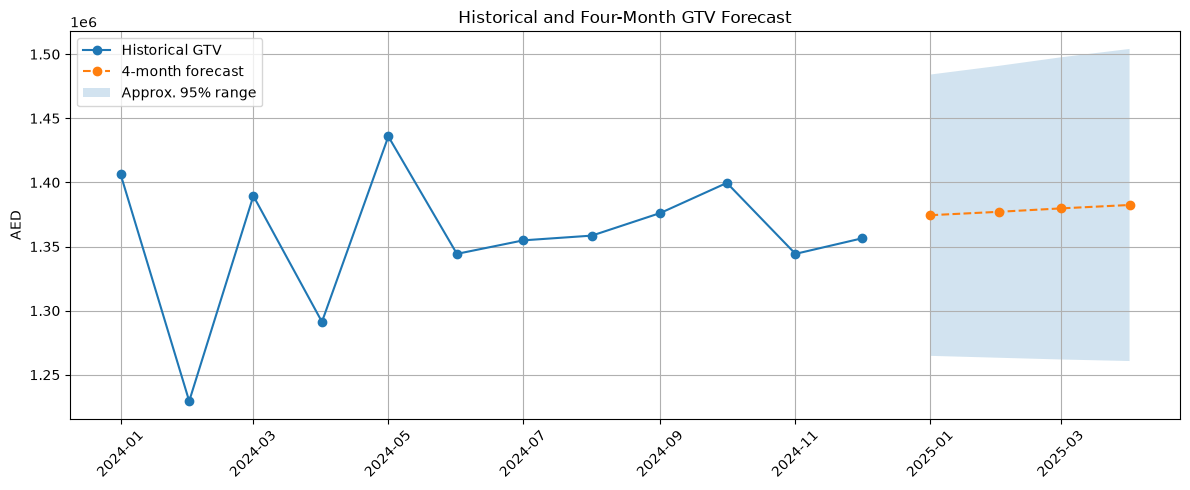

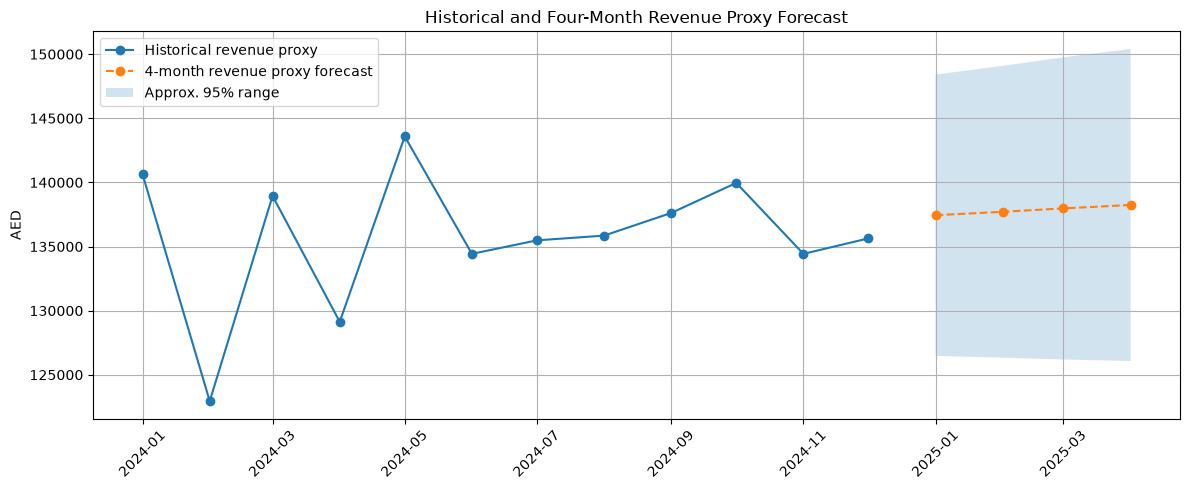

In [12]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(monthly["month"], monthly["gtv_aed"], marker="o", label="Historical GTV")
ax.plot(forecast["month"], forecast["forecast_gtv_aed"], marker="o", linestyle="--", label="4-month forecast")
ax.fill_between(forecast["month"], forecast["gtv_lower_approx_aed"], forecast["gtv_upper_approx_aed"], alpha=0.2, label="Approx. 95% range")
ax.set_title("Historical and Four-Month GTV Forecast")
ax.set_ylabel("AED"); ax.grid(True); ax.legend(); plt.xticks(rotation=45); plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(monthly["month"], monthly["estimated_revenue_aed"], marker="o", label="Historical revenue proxy")
ax.plot(forecast["month"], forecast["forecast_revenue_proxy_aed"], marker="o", linestyle="--", label="4-month revenue proxy forecast")
ax.fill_between(forecast["month"], forecast["revenue_lower_approx_aed"], forecast["revenue_upper_approx_aed"], alpha=0.2, label="Approx. 95% range")
ax.set_title("Historical and Four-Month Revenue Proxy Forecast")
ax.set_ylabel("AED"); ax.grid(True); ax.legend(); plt.xticks(rotation=45); plt.tight_layout(); plt.show()

### Forecast validation and limitations
This is a monthly linear-trend baseline, not a seasonality-aware or causal forecast. It assumes the historical trend continues. If there are fewer than 18–24 monthly observations, avoid claiming stable annual seasonality. Before business use, compare at least: last-month naive, seasonal-naive (only with enough history), moving average, ETS/ARIMA, and a machine-learning model using rolling-origin backtesting. Report MAE, RMSE, sMAPE/WAPE and prediction intervals. Do not interpret the approximate residual band as a statistically guaranteed interval.

## 7. Revenue definition and Finance reconciliation

In [13]:
revenue_definition = pd.DataFrame([
    ["Gross transaction value (GTV)", "Sum of positive transaction amounts", "Can be computed from amount_aed"],
    ["Platform/merchant revenue", "GTV x contracted take rate or fee schedule", "Requires contract, discounts, refunds and fee rules"],
    ["Recognized accounting revenue", "Revenue recognized under applicable accounting policy", "Requires Finance ledger and accounting rules"],
    ["Net revenue", "Recognized revenue less refunds/adjustments as defined by Finance", "Requires refunds, reversals, taxes and ledger reconciliation"],
], columns=["Measure", "Definition", "Evidence needed"])
display(revenue_definition)

,Measure,Definition,Evidence needed
0,Gross transaction value (GTV),Sum of positive transaction amounts,Can be computed from amount_aed
1,Platform/merchant revenue,GTV x contracted take rate or fee schedule,"Requires contract, discounts, refunds and fee ..."
2,Recognized accounting revenue,Revenue recognized under applicable accounting...,Requires Finance ledger and accounting rules
3,Net revenue,Recognized revenue less refunds/adjustments as...,"Requires refunds, reversals, taxes and ledger ..."


## 8. Fraud loss-prevention strategy: how to reduce future fraud

### A. Prevention before authorization
- **Identity and account security:** verified email/phone, risk-based step-up authentication, MFA for sensitive account changes, bot and credential-stuffing controls, device/session integrity.
- **Payment controls:** 3-D Secure where appropriate, issuer/processor risk signals, velocity limits by card/account/device/IP, BIN-country and shipping/billing consistency checks.
- **Adaptive friction:** approve low-risk transactions, step-up authenticate medium-risk transactions, route high-risk cases to trained manual review; avoid blanket declines based on one weak signal.
- **Account takeover:** detect password resets, new device, address changes and payment-instrument changes shortly before purchase.
- **Merchant controls:** monitor unusual refund/return patterns, coupon abuse, gift-card abuse and merchant-level fraud spikes.

### B. Detection and response after authorization
- Queue risk-ranked cases for review with reason codes and evidence.
- Use chargeback outcomes as delayed labels only after their true availability time.
- Maintain a case-management workflow: assign owner, SLA, evidence, decision, customer impact, and final outcome.
- Feed confirmed outcomes back into training only after label-quality checks and point-in-time reconstruction.
- Maintain an allowlist/denylist governance process with expiry, audit trail and appeal path.

### C. Performance and customer safeguards
- Track fraud loss rate, chargeback rate, fraud dollars prevented, approval rate, false-decline rate, manual-review rate, review SLA, customer abandonment, and segment fairness.
- Review thresholds by expected monetary value and capacity—not accuracy alone.
- Monitor drift by country, payment method, merchant category, device, customer tenure and transaction amount.
- Require human oversight for consequential declines and provide a customer recovery/appeal path.

## 9. Fraud policy economics: scenario template (not an approved business case)

In [14]:
# This is a transparent scenario calculator. Replace every assumption with Risk/Finance-approved values.
ASSUMED_CHARGEBACK_FEE_AED = 25.0
ASSUMED_REVIEW_COST_AED = 8.0
ASSUMED_FRAUD_LOSS_RATE = 0.20  # illustrative fraction of transaction amount lost
ASSUMED_REVIEW_CAPACITY_PER_MONTH = 500  # replace with actual staffed capacity

# Calculate fraud exposure on the full observed dataset. This is not necessarily actual realized loss.
scenario = df.copy()
scenario["amount_nonnegative"] = scenario[AMOUNT_COL].clip(lower=0)
scenario["estimated_fraud_exposure_aed"] = np.where(
    scenario[LABEL_COL] == 1,
    scenario["amount_nonnegative"] * ASSUMED_FRAUD_LOSS_RATE + ASSUMED_CHARGEBACK_FEE_AED,
    0.0
)
print("Illustrative labeled fraud exposure (AED):",
      round(scenario["estimated_fraud_exposure_aed"].sum(), 2))
print("Review capacity assumption per month:", ASSUMED_REVIEW_CAPACITY_PER_MONTH)
print("NOTE: No operational policy savings are claimed without calibrated out-of-time scores, review outcomes and real cost data.")

Illustrative labeled fraud exposure (AED): 530941.66
Review capacity assumption per month: 500
NOTE: No operational policy savings are claimed without calibrated out-of-time scores, review outcomes and real cost data.


## 10. Model baseline and point-in-time-safe feature preparation

In [15]:
# Keep feature engineering conservative. Exclude target, identifiers, post-outcome fields,
# and any features whose timestamps are unverified.
known_leakage_or_outcome = {
    LABEL_COL, "transaction_id", "fraud_flag_ip", "fraud_flag_mismatch",
    "fraud_flag_velocity", "fraud_flag_new_account", "fraud_flag_prev_cb",
    "fraud_flag_odd_hour"
}
unsafe_until_verified = {
    "transactions_last_1h", "transactions_last_24h", "ip_risk_score",
    "user_prev_chargebacks", "user_is_high_risk"
}
exclude = known_leakage_or_outcome | unsafe_until_verified | {DATE_COL}
candidate = [c for c in df.columns if c not in exclude]
# Avoid raw IDs and free-form/high-cardinality fields unless deliberately governed.
candidate = [c for c in candidate if c not in {"user_id", "ip_address"}]
print("Candidate predictors:", candidate)
print("Excluded pending evidence:", sorted(unsafe_until_verified.intersection(df.columns)))

Candidate predictors: ['amount_aed', 'currency', 'payment_method', 'device_type', 'browser', 'merchant_category', 'items_count', 'avg_item_price', 'shipping_city', 'billing_city', 'shipping_billing_match', 'card_present', 'bin_country', 'card_age_days', 'card_country_match', 'email_domain', 'user_account_age_days', 'local_hour', 'odd_hour', 'data_source', 'account_age_negative_flag', 'account_age_days_validated']
Excluded pending evidence: ['ip_risk_score', 'transactions_last_1h', 'transactions_last_24h', 'user_is_high_risk', 'user_prev_chargebacks']


In [16]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score, precision_recall_fscore_support
from sklearn.dummy import DummyClassifier

model_df = df.dropna(subset=[DATE_COL, LABEL_COL]).sort_values(DATE_COL).copy()
# Use only candidate fields that actually exist in the cleaned frame.
features = [c for c in candidate if c in model_df.columns]
X = model_df[features].copy()
y = model_df[LABEL_COL].astype(int)

# Remove columns that are entirely missing or have only one non-null value.
features = [c for c in features if X[c].notna().any() and X[c].nunique(dropna=True) > 1]
X = X[features]
numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = [c for c in X.columns if c not in numeric_features]

numeric_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer([
    ("num", numeric_pipe, numeric_features),
    ("cat", categorical_pipe, categorical_features)
])

split1 = int(len(model_df)*0.70)
split2 = int(len(model_df)*0.85)
X_train, X_val, X_test = X.iloc[:split1], X.iloc[split1:split2], X.iloc[split2:]
y_train, y_val, y_test = y.iloc[:split1], y.iloc[split1:split2], y.iloc[split2:]

baseline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE))
])
baseline.fit(X_train, y_train)
test_prob = baseline.predict_proba(X_test)[:, 1]
print("Temporal split sizes:", len(X_train), len(X_val), len(X_test))
print("Test ROC-AUC:", round(roc_auc_score(y_test, test_prob), 4))
print("Test PR-AUC:", round(average_precision_score(y_test, test_prob), 4))

Temporal split sizes: 70000 15000 15000
Test ROC-AUC: 0.6002
Test PR-AUC: 0.1247


## 11. Optional deep learning: PyTorch MLP baseline (CPU)

In [17]:
# Optional. Run only if PyTorch is installed. This MLP is a learning benchmark,
# not automatically better than the Logistic Regression baseline.
try:
    import torch
    from torch import nn
    from torch.utils.data import TensorDataset, DataLoader
    from sklearn.metrics import average_precision_score, roc_auc_score
    from sklearn.utils.class_weight import compute_class_weight

    Xtr = preprocessor.fit_transform(X_train)
    Xte = preprocessor.transform(X_test)
    if hasattr(Xtr, "toarray"): Xtr = Xtr.toarray()
    if hasattr(Xte, "toarray"): Xte = Xte.toarray()
    Xtr = np.asarray(Xtr, dtype=np.float32)
    Xte = np.asarray(Xte, dtype=np.float32)
    ytr = y_train.to_numpy(dtype=np.float32)
    yte = y_test.to_numpy(dtype=np.float32)

    torch.manual_seed(RANDOM_STATE)
    device = torch.device("cpu")
    train_ds = TensorDataset(torch.tensor(Xtr), torch.tensor(ytr))
    loader = DataLoader(train_ds, batch_size=512, shuffle=True)
    class_counts = np.bincount(y_train.to_numpy(), minlength=2)
    pos_weight = torch.tensor([class_counts[0] / max(class_counts[1], 1)], dtype=torch.float32)

    class FraudMLP(nn.Module):
        def __init__(self, n_features):
            super().__init__()
            self.net = nn.Sequential(
                nn.Linear(n_features, 128), nn.ReLU(), nn.Dropout(0.25),
                nn.Linear(128, 64), nn.ReLU(), nn.Dropout(0.20),
                nn.Linear(64, 1)
            )
        def forward(self, x): return self.net(x).squeeze(1)

    torch_model = FraudMLP(Xtr.shape[1]).to(device)
    optimizer = torch.optim.AdamW(torch_model.parameters(), lr=1e-3, weight_decay=1e-4)
    loss_fn = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
    for epoch in range(12):
        torch_model.train()
        epoch_losses = []
        for xb, yb in loader:
            optimizer.zero_grad()
            loss = loss_fn(torch_model(xb), yb)
            loss.backward()
            optimizer.step()
            epoch_losses.append(loss.item())
        print(f"Epoch {epoch+1:02d} | loss={np.mean(epoch_losses):.4f}")

    torch_model.eval()
    with torch.no_grad():
        torch_prob = torch.sigmoid(torch_model(torch.tensor(Xte))).numpy()
    print("PyTorch test ROC-AUC:", round(roc_auc_score(yte, torch_prob), 4))
    print("PyTorch test PR-AUC:", round(average_precision_score(yte, torch_prob), 4))
except ImportError:
    print("PyTorch not installed. Optional install: pip install torch")
except Exception as e:
    print("Deep-learning experiment skipped due to:", repr(e))

Epoch 01 | loss=1.2566
Epoch 02 | loss=1.2405
Epoch 03 | loss=1.2340
Epoch 04 | loss=1.2299
Epoch 05 | loss=1.2258
Epoch 06 | loss=1.2229
Epoch 07 | loss=1.2196
Epoch 08 | loss=1.2175
Epoch 09 | loss=1.2125
Epoch 10 | loss=1.2092
Epoch 11 | loss=1.2063
Epoch 12 | loss=1.1996
PyTorch test ROC-AUC: 0.5909
PyTorch test PR-AUC: 0.1192


## 12. NLP: only train when genuine text exists and is authorized

In [18]:
# No text is synthesized. Candidate fields must contain actual customer/merchant text,
# have an approved legal basis, and pass PII redaction before model training.
TEXT_CANDIDATES = ["customer_review", "support_message", "order_note", "merchant_description", "chargeback_reason_text"]
text_cols = [c for c in TEXT_CANDIDATES if c in df.columns]
if not text_cols:
    print("NLP skipped: no genuine text field exists in this dataset.")
else:
    print("Potential genuine text columns found:", text_cols)
    print("Before NLP: verify provenance, consent/legal basis, PII redaction, label timing and train/test separation.")

NLP skipped: no genuine text field exists in this dataset.


## 13. Cloud deployment architecture and production readiness

### Recommended secure architecture (Azure or AWS)
1. **Ingestion:** API gateway / event hub (Azure Event Hubs or AWS Kinesis), schema validation, idempotency key, event-time timestamp.
2. **Storage:** encrypted raw immutable landing zone (ADLS/S3) plus curated warehouse/lakehouse; strict role-based access and retention.
3. **Feature layer:** point-in-time feature computation with event-time windows; online/offline parity and feature freshness checks.
4. **Training:** versioned training pipeline, time-based splits, experiment tracking, model registry, signed artifacts and reproducible environment.
5. **Serving:** private containerized inference API behind gateway; managed identity/workload identity, secrets vault, TLS, rate limits, input validation.
6. **Decision orchestration:** rules + model score + human-review queue; fail-safe fallback; no silent auto-decline during pilot.
7. **Observability:** latency, availability, feature missingness, drift, score distribution, calibration, fraud outcomes, false declines and review capacity.
8. **Governance:** model card, data card, approval gates, rollback, audit logs, incident response, periodic fairness and security reviews.

**Do not deploy the current synthetic model to real payments.** First replace synthetic data with authorized production data and complete leakage, privacy, security, performance and controlled-pilot validation.

In [19]:
production_gate = pd.DataFrame([
    ["Production source provenance", "BLOCKED", "Current data is synthetic; obtain source-owner evidence."],
    ["Point-in-time feature audit", "BLOCKED", "Velocity, IP risk and historical chargeback timestamps unverified."],
    ["Negative account-age root cause", "BLOCKED", "Investigate source-generation and event-time logic."],
    ["Risk/Finance cost approval", "BLOCKED", "Validate chargeback loss, margin, review cost and staffing capacity."],
    ["Temporal backtesting", "REQUIRED", "Rolling-origin validation on authorized real data."],
    ["Security/privacy assessment", "REQUIRED", "Threat model, access control, encryption, retention and legal review."],
    ["Controlled pilot", "NOT STARTED", "Shadow mode, human review, guardrails and rollback."],
    ["Production deployment", "NOT APPROVED", "Proof of concept only."]
], columns=["Gate", "Status", "Required action"])
display(production_gate)

,Gate,Status,Required action
0,Production source provenance,BLOCKED,Current data is synthetic; obtain source-owner...
1,Point-in-time feature audit,BLOCKED,"Velocity, IP risk and historical chargeback ti..."
2,Negative account-age root cause,BLOCKED,Investigate source-generation and event-time l...
3,Risk/Finance cost approval,BLOCKED,"Validate chargeback loss, margin, review cost ..."
4,Temporal backtesting,REQUIRED,Rolling-origin validation on authorized real d...
5,Security/privacy assessment,REQUIRED,"Threat model, access control, encryption, rete..."
6,Controlled pilot,NOT STARTED,"Shadow mode, human review, guardrails and roll..."
7,Production deployment,NOT APPROVED,Proof of concept only.


## 14. Executive recommendations and action plan

| Priority | Recommendation | Action / evidence | Owner |
|---|---|---|---|
| P0 | Verify velocity, IP risk and chargeback timestamps | Reconstruct as-of values; compare every feature timestamp with transaction decision time; remove any post-event values | Data Engineering + Risk |
| P0 | Investigate negative account ages | Reconcile account creation and transaction timestamps, timezone, user joins and generator logic; document disposition | Data Engineering |
| P0 | Confirm review capacity and economics | Finance signs off on realized fraud loss, chargeback fees, refunds, take rate and review cost; Risk confirms cases/day and SLA | Risk + Finance |
| P0 | Establish verified production provenance | Source owner, extraction query/job, access authorization, data lineage, row reconciliation and checksum | Data Owner + Security |
| P1 | Run temporal model validation | Rolling-origin backtests, PR-AUC, recall at fixed review capacity, calibration, false-decline and segment metrics | Data Science |
| P1 | Add customer protection controls | Step-up authentication, account takeover signals, review/appeal workflow, reason codes and audit log | Product + Risk |
| P1 | Build monitoring and rollback | Drift, latency, missingness, score distribution, fraud outcomes, review backlog and rollback trigger | ML Engineering |
| P2 | Test deep learning and NLP | Compare PyTorch model against strong tree/linear baselines; NLP only on genuine authorized text | Data Science |
| P2 | Controlled pilot | Start shadow mode, then limited human-reviewed pilot with predefined stop conditions | Risk + Operations |

## 15. Save reproducible outputs

In [20]:
# Save analysis outputs. These files are derived from the loaded synthetic dataset unless provenance is independently verified.
monthly.to_csv("monthly_sales_gtv_revenue_proxy.csv", index=False)
forecast.to_csv("four_month_sales_revenue_forecast.csv", index=False)
leakage_audit.to_csv("point_in_time_leakage_audit.csv", index=False)
production_gate.to_csv("production_readiness_gates.csv", index=False)
with open("data_provenance_manifest.json", "w", encoding="utf-8") as f:
    json.dump(provenance, f, indent=2, default=str)

print("Saved:")
for filename in [
    "monthly_sales_gtv_revenue_proxy.csv",
    "four_month_sales_revenue_forecast.csv",
    "point_in_time_leakage_audit.csv",
    "production_readiness_gates.csv",
    "data_provenance_manifest.json"
]:
    print(" -", filename)

Saved:
 - monthly_sales_gtv_revenue_proxy.csv
 - four_month_sales_revenue_forecast.csv
 - point_in_time_leakage_audit.csv
 - production_readiness_gates.csv
 - data_provenance_manifest.json


## Final conclusion

The enhanced project combines fraud detection, sales/GTV analysis, a four-month forecast, a revenue proxy, data provenance controls, leakage investigation, negative account-age diagnostics, optional PyTorch experimentation, conditional NLP, and a cloud production roadmap.

**Current status: Proof of concept using synthetic data.** The next critical milestone is not a larger neural network or immediate cloud deployment; it is obtaining verified authorized production data, resolving point-in-time feature integrity and negative account ages, and getting Risk/Finance approval for the operating policy. The four-month sales and revenue outputs are forecasts based on the observed synthetic history and the explicitly stated revenue take-rate assumption.